In [57]:
# load the space
from input_station import DB_s08
space = DB_s08(0).GLOD4()

6


In [90]:
# calculate solid angle for a single point/object
# pick a single non-perm object, // l
# size of the bounding box of the object 
object_mesh = space["Furn_chairs_059_Group44_ID_9102699b_dd66_4d1b_8956_a44a23710c92"]["mesh"]
observation_point = object_mesh.centroid

# pick all the windows of the same space
windows = space["perm_windows_glass"]["mesh"]
window_triangles = space["perm_windows_glass"]["mesh"].triangles

# calculate the cumulative solid angle for that object, seen by the windows.
# calculate solid angle for each object
import numpy as np
def solid_angle(triangles: np.ndarray, point: np.ndarray) -> float:
    """
    Calculate the clumulative solid angle subtended by the mesh triangles from the point.
    
    Parameters:
    triangles (numpy.ndarray): Array of triangles, shape (n, 3, 3)
    point (numpy.ndarray): Observation point, shape (3,)
    
    Returns:
    float: Solid angle in steradians
    """
    def signed_volume(a, b, c, d):
        return np.dot(np.cross(b - a, c - a), d - a) / 6.0

    total_solid_angle = 0.0
    
    for tri in triangles:
        a, b, c = tri - point
        norm = np.linalg.norm(np.cross(b - a, c - a))
        volume = signed_volume(a, b, c, np.array([0.0, 0.0, 0.0]))
        angle = 2 * np.arctan2(volume, np.dot(a, b) * np.linalg.norm(c) + 
                                      np.dot(b, c) * np.linalg.norm(a) + 
                                      np.dot(c, a) * np.linalg.norm(b))
        total_solid_angle += angle
    
    return np.abs(total_solid_angle)
solid_angle(window_triangles, observation_point)

0.011896694813938331

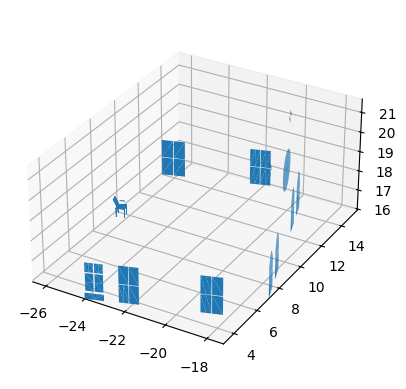

In [88]:
# visualize all the objects in the space 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Print the object triangles
for triangle in object_mesh.triangles:
    poly = Poly3DCollection([triangle])
    ax.add_collection3d(poly)

for triangle in windows.triangles:
    poly = Poly3DCollection([triangle])
    ax.add_collection3d(poly)
    

# Set plot limits (optional, adjust according to your data)
ax.set_xlim([min(windows.triangles[:,:,0].flatten()), max(windows.triangles[:,:,0].flatten())])
ax.set_ylim([min(windows.triangles[:,:,1].flatten()), max(windows.triangles[:,:,1].flatten())])
ax.set_zlim([min(windows.triangles[:,:,2].flatten()), max(windows.triangles[:,:,2].flatten())])

# aspect ratio of the plot equal
ax.set_box_aspect([np.ptp(windows.triangles[:,:,0].flatten()), 
                   np.ptp(windows.triangles[:,:,1].flatten()), 
                   np.ptp(windows.triangles[:,:,2].flatten())])
plt.show()

In [89]:
import plotly.graph_objects as go
import numpy as np

# Assuming object_mesh.triangles and windows.triangles are numpy arrays with shape (n, 3, 3)

# Function to create plotly mesh
def create_mesh(triangles, color):
    x, y, z = triangles[:, :, 0].flatten(), triangles[:, :, 1].flatten(), triangles[:, :, 2].flatten()
    I = np.arange(0, len(x), 3)
    J = np.arange(1, len(x), 3)
    K = np.arange(2, len(x), 3)
    mesh = go.Mesh3d(
        x=x,
        y=y,
        z=z,
        i=I,
        j=J,
        k=K,
        color=color,
        opacity=0.50
    )
    return mesh

# Create traces for object_mesh and windows
object_trace = create_mesh(object_mesh.triangles, 'blue')
windows_trace = create_mesh(windows.triangles, 'green')

# Create the figure
fig = go.Figure(data=[object_trace, windows_trace])

# Update layout for better visualization
fig.update_layout(
    scene=dict(
        xaxis=dict(nticks=10, range=[min(windows.triangles[:, :, 0].flatten()), max(windows.triangles[:, :, 0].flatten())]),
        yaxis=dict(nticks=10, range=[min(windows.triangles[:, :, 1].flatten()), max(windows.triangles[:, :, 1].flatten())]),
        zaxis=dict(nticks=10, range=[min(windows.triangles[:, :, 2].flatten()), max(windows.triangles[:, :, 2].flatten())])
    ),
    width=700,
    margin=dict(r=20, l=10, b=10, t=10)
)

fig.show()


ModuleNotFoundError: No module named 'plotly'